# 02 — Features: raw pixels vs HOG

Every model in this study sees each image as one of two feature vectors:
1. **Raw pixels:** the 28×28 image flattened to 784 numbers.
2. **HOG (Histogram of Oriented Gradients):** a description of the *edges and their directions* in each small region.

This notebook explains both, picks the HOG settings on the **validation set** (never test), shows what HOG "sees", and
caches the train/val features so phases 03–04 don't recompute them.

> **No-leakage notes.** Neither extractor learns anything from data (they're fixed formulas applied to one image at a time).
> HOG settings are chosen by validation accuracy only. Test features are **not** built here; `final_test_run()` builds them
> the first time a model is tested (AGENTS.md §4).

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd() if (pathlib.Path.cwd() / "src").exists() else pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage.feature import hog
from skimage import exposure

from src import config
from src.data import load_splits
from src.features import get_features, get_labels, run_hog_sweep, hog_tag
from src.utils import set_seed, save_fig, Timer

set_seed()
CLASS_NAMES = config.CLASS_NAMES
print("HOG config in use:", config.HOG_PARAMS, "->", hog_tag(config.HOG_PARAMS))

HOG config in use: {'orientations': 12, 'pixels_per_cell': (4, 4), 'cells_per_block': (2, 2)} -> o12_p4_c2


## 1. Raw pixel features
Flatten each 28×28 image into a 784-long vector. Simple, but it **throws away the 2-D neighbourhood**: the model doesn't
know that pixel 0 and pixel 28 are vertical neighbours, and a shirt shifted by two pixels looks like a completely different vector.

Values stay in [0, 1]. **No scaling happens here.** Models that need scaling do it inside their own Pipeline (section 6).

In [2]:
for split in ["train", "val", "trainval"]:
    F = get_features("pixels", split)
    print(f"pixels {split:9s} {F.shape}  dtype={F.dtype}  range=[{F.min():.1f}, {F.max():.1f}]")

pixels train     (54000, 784)  dtype=float32  range=[0.0, 1.0]
pixels val       (6000, 784)  dtype=float32  range=[0.0, 1.0]
pixels trainval  (60000, 784)  dtype=float32  range=[0.0, 1.0]


## 2. How HOG works
For each image:
1. **Gradients:** at every pixel, measure how fast brightness changes horizontally and vertically, giving an edge
   *strength* and *direction*.
2. **Cells:** split the image into small cells (e.g. 4×4 pixels). In each cell, build a histogram of edge directions
   (`orientations` bins), with each pixel's vote weighted by its edge strength.
3. **Blocks:** group neighbouring cells (e.g. 2×2) and normalise their histograms together (L2-Hys). This makes the
   description robust to brightness and contrast changes.
4. Concatenate all block histograms into one vector.

Length for a 28×28 image with cell size *c*, block size *b* and *o* bins: ((28/c) − b + 1)² × b² × o.
For our final config (o=12, c=4, b=2): 6² × 4 × 12 = **1,728**.

**Why HOG might help:** it encodes *shape* (collars, sleeves, soles) and ignores brightness.
**Why it might hurt:** at 28×28 there is very little fine texture left, and a cell histogram forgets *where* inside the cell an edge was.

## 3. Choosing the HOG settings on the validation set
We tried 3 × 2 × 2 = 12 configs. For each, a quick **proxy** linear SVM (SGD with hinge loss, fixed 30 passes, D-016)
was trained on the 54k train features and scored on the 6k **val** features. The proxy only *ranks* configs; it isn't
one of the study's models. The sweep takes ~2.5 min, so by default we load its saved table; set `RERUN_SWEEP = True` to recompute it.

In [3]:
RERUN_SWEEP = False
if RERUN_SWEEP or not config.HOG_SWEEP_PATH.exists():
    with Timer("HOG sweep"):
        sweep = run_hog_sweep()
else:
    sweep = pd.read_csv(config.HOG_SWEEP_PATH)
sweep = sweep.assign(config=[hog_tag(r) for r in sweep.to_dict("records")])
sweep.sort_values("val_acc", ascending=False)[["config", "dim", "extract_s_per_1000", "val_acc"]].reset_index(drop=True)

,config,dim,extract_s_per_1000,val_acc
0,o12_p4_c2,1728,0.216,0.8818
1,o9_p4_c2,1296,0.212,0.8783
2,o6_p4_c2,864,0.210,0.8757
3,o12_p4_c1,588,0.224,0.8630
4,o9_p4_c1,441,0.226,0.8533
5,o6_p4_c1,294,0.225,0.8483
6,o12_p7_c2,432,0.082,0.8357
7,o9_p7_c2,324,0.086,0.8328
8,o6_p7_c2,216,0.079,0.8188
9,o12_p7_c1,192,0.103,0.8010


saved results/figures/features_hog_sweep.png


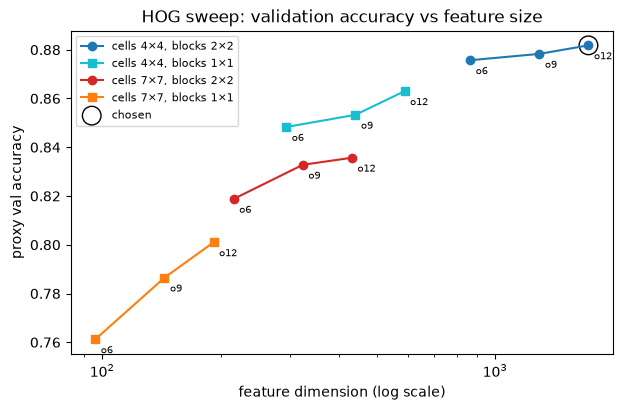

In [4]:
fig, ax = plt.subplots(figsize=(7, 4.2))
styles = {(4, 2): ("tab:blue", "o"), (4, 1): ("tab:cyan", "s"), (7, 2): ("tab:red", "o"), (7, 1): ("tab:orange", "s")}
for (ppc, cpb), (color, marker) in styles.items():
    part = sweep[(sweep.pixels_per_cell == ppc) & (sweep.cells_per_block == cpb)]
    ax.plot(part.dim, part.val_acc, marker=marker, color=color, label=f"cells {ppc}×{ppc}, blocks {cpb}×{cpb}")
    for _, r in part.iterrows():
        ax.annotate(f"o{r.orientations}", (r.dim, r.val_acc), textcoords="offset points", xytext=(4, -10), fontsize=7)
chosen = sweep.loc[sweep.val_acc.idxmax()]
ax.scatter([chosen.dim], [chosen.val_acc], s=180, facecolors="none", edgecolors="black", label="chosen")
ax.set_xscale("log"); ax.set_xlabel("feature dimension (log scale)"); ax.set_ylabel("proxy val accuracy")
ax.set_title("HOG sweep: validation accuracy vs feature size"); ax.legend(fontsize=8)
save_fig(fig, "features_hog_sweep"); plt.show()

**Reading the sweep**
- **Small cells win by a lot** (4×4 beats 7×7 by 4–8 points). A 7×7 cell is a quarter of the image width, so it blurs the outline.
- **Block normalisation helps** (2×2 blocks beat 1×1 by 2–3 points).
- **More orientation bins help a little** (12 > 9 > 6).
- **Chosen: o12, 4×4 cells, 2×2 blocks (1,728-d), val accuracy 0.8818.** The runner-up o9 (1,296-d) scores 0.8783. The rule fixed
  in advance was "highest val accuracy; within 0.3 points prefer the smaller one". The gap is 0.35, so o12 is chosen (D-017).
- Extraction cost is small for all configs: ~0.2 s per 1,000 images.

## 4. What HOG "sees"
One training image per class next to its HOG picture (each little star = the edge directions in one cell; brighter = stronger edges).

saved results/figures/features_hog_examples.png


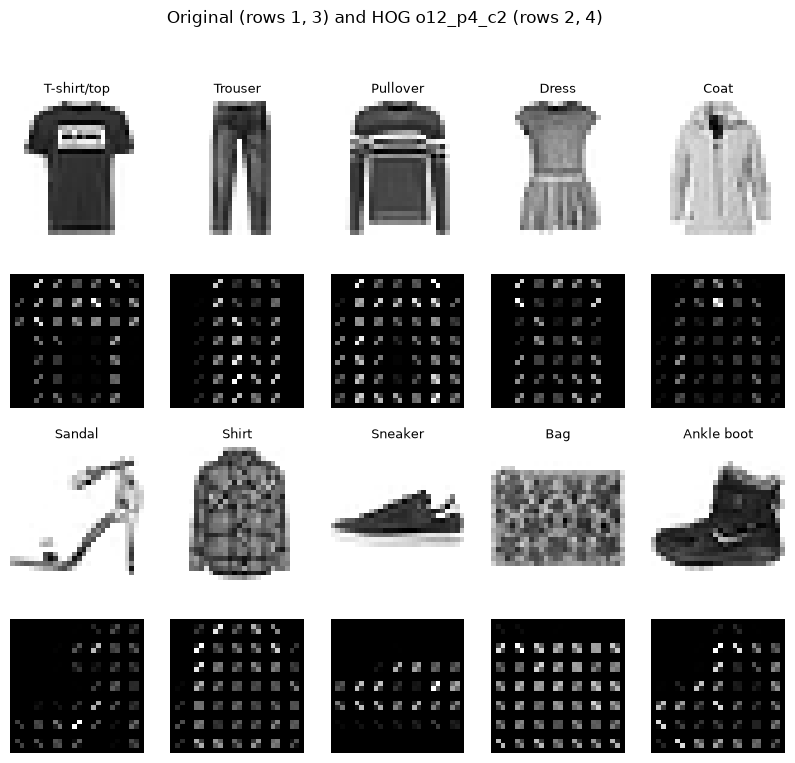

In [5]:
s = load_splits(verbose=False)
X_train, y_train = s["X_train"], s["y_train"]
del s  # only training images are shown

p = config.HOG_PARAMS
fig, axes = plt.subplots(4, 5, figsize=(10, 8.6))
for c in range(config.NUM_CLASSES):
    img = X_train[np.where(y_train == c)[0][0]]
    _, hog_img = hog(img, orientations=p["orientations"], pixels_per_cell=p["pixels_per_cell"],
                     cells_per_block=p["cells_per_block"], block_norm="L2-Hys", visualize=True)
    row, col = (c // 5) * 2, c % 5
    axes[row, col].imshow(img, cmap="gray_r"); axes[row, col].set_title(CLASS_NAMES[c], fontsize=9)
    axes[row + 1, col].imshow(exposure.rescale_intensity(hog_img, in_range=(0, hog_img.max())), cmap="gray")
for ax in axes.flat:
    ax.axis("off")
fig.suptitle(f"Original (rows 1, 3) and HOG {hog_tag(p)} (rows 2, 4)")
save_fig(fig, "features_hog_examples"); plt.show()

Each picture is a 7×7 grid of cells; each "star" shows which edge directions dominate in that cell.
- The four **tops** (T-shirt, pullover, coat, shirt) fill the same grid area with a similar torso + sleeves outline. A collar,
  a zip or buttons change only a few cells, so HOG alone may still confuse them.
- **Texture also creates edges.** The checked shirt (like the patterned bag) has strong edges in almost every cell, so a
  shirt's HOG can look "busy" for reasons unrelated to its shape. This can help (it's a shirt-like texture) or hurt (a patterned bag).
- **Shoes and trousers** have distinctive edge layouts (a diagonal sole line, two vertical legs), so HOG should separate them well.

## 5. Build and cache the final HOG features (train / val / trainval)
These files go to `features/` (gitignored). Phases 03–04 load them instantly. ⏱ ~20 s.

In [6]:
for split in ["train", "val", "trainval"]:
    with Timer(f"hog {split}"):
        F = get_features("hog", split)
    print(f"   hog {split:9s} {F.shape}  dtype={F.dtype}")
assert np.array_equal(get_labels("trainval")[:54000], y_train)  # row order check: trainval = train then val

hog train: 0.1s
   hog train     (54000, 1728)  dtype=float32


hog val: 0.0s
   hog val       (6000, 1728)  dtype=float32


hog trainval: 0.2s
   hog trainval  (60000, 1728)  dtype=float32


## 6. Why scaling matters for some models but not others
Pixel features range from 0 to 1, but many border pixels are almost always 0 while centre pixels vary a lot. HOG values
have their own, different spread. Look at how unequal the per-feature spreads are:

saved results/figures/features_scale_spread.png


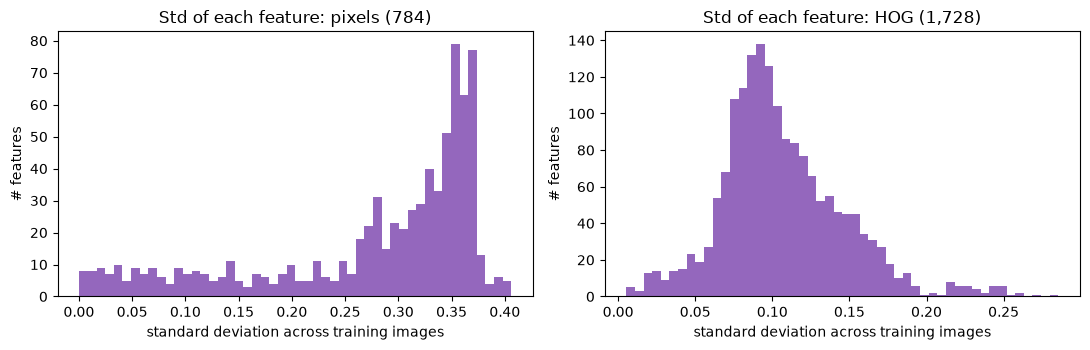

pixels: 11 of 784 features are almost constant (std < 0.01)


In [7]:
P, H = get_features("pixels", "train"), get_features("hog", "train")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, F, name in [(axes[0], P, "pixels (784)"), (axes[1], H, f"HOG (1,728)")]:
    ax.hist(F.std(axis=0), bins=50, color="tab:purple")
    ax.set_title(f"Std of each feature: {name}"); ax.set_xlabel("standard deviation across training images"); ax.set_ylabel("# features")
fig.tight_layout(); save_fig(fig, "features_scale_spread"); plt.show()
print(f"pixels: {np.sum(P.std(axis=0) < 0.01)} of 784 features are almost constant (std < 0.01)")

- **Logistic Regression and SVM** are trained by optimisation with a regularisation penalty that treats every
  weight the same. Unscaled features make that penalty unfair and slow down convergence.
- **kNN** uses distances, so a feature with a large spread dominates the distance.
- **Random Forest** splits one feature at a time on a threshold ("is pixel 300 > 0.4?"), and rescaling doesn't change
  which split is best. **So RF needs no scaling.**

So LR, kNN and SVM get `StandardScaler` (subtract mean, divide by std) **inside their Pipeline**. That way the mean/std are
learned only from the rows the model is trained on (train during tuning, 60k train+val in the final fit), never from val or test (D-004).

## 7. Summary

- **Pixels:** 784-d, values in [0, 1], plain flatten. Cached for train / val / trainval.
- **HOG:** chosen on validation accuracy from a 12-config sweep. **o12, 4×4 cells, 2×2 blocks → 1,728-d** (proxy val acc 0.8818).
  Small cells and block normalisation matter most. Cached for train / val / trainval (~15 s to build).
- **Test features are not built here.** They're created by `final_test_run()` the first time a model is tested.
- **Scaling:** LR, kNN and SVM put a `StandardScaler` inside their Pipeline; RF doesn't need one.
- **What to watch in phases 03–04 (RQ2):** whether HOG beats pixels overall, and especially whether it helps on the tops
  (Shirt / Coat / Pullover / T-shirt) that the EDA flagged as nearly identical in pixel space.
- The proxy's 0.88 on HOG is only a ranking tool, not a result. Final numbers come from the tuned models.